# ⚙️ Stage 4 & 5: Data Preprocessing, Feature Engineering & Selection

## Project Lifecycle Stage
- **Stage 1**: Problem Definition ✅
- **Stage 2**: Data Collection ✅
- **Stage 3**: Exploratory Data Analysis (EDA) ✅
- **Stage 4**: **Data Cleaning & Preprocessing [ACTIVE]** ⚙️
- **Stage 5**: **Feature Engineering & Selection [ACTIVE]** 🛠️
- **Stage 6**: Model Selection & Training [UPCOMING] ⏳

---

## Objectives of This Notebook
1. **Prevent Data Leakage**: Execute **Stratified 80/20 Train-Test Partitioning** before any transformations or scalers.
2. **Domain-Driven Feature Engineering**: Construct 7 clinically and statistically motivated interaction variables discovered during EDA.
3. **Robust Feature Scaling**: Evaluate `RobustScaler` (median/IQR) on right-skewed variables (`BMI`, `PhysHlth`, `MentHlth`, `Unhealthy_Days_Total`), fitting strictly on the training partition.
4. **Feature Importance & Selection**: Quantify predictive power using **Mutual Information** and **Tree-Based (Random Forest) Gini Importance**.
5. **Class Imbalance Strategy**: Benchmark inverse class weighting vs. Synthetic Minority Over-sampling (`SMOTE`) strictly on training folds.
6. **Dataset Serialization**: Export finalized sets (`X_train`, `X_test`, `X_train_scaled`, `X_test_scaled`, `y_train`, `y_test`) into `data/processed/` for model training.

---
## 1. Environment Setup & Data Loading

We import the required scientific libraries: `pandas`, `numpy`, `scipy`, `matplotlib`, `seaborn`, `sklearn`, and `imblearn`.

In [1]:
import sys
import os
from pathlib import Path
import json
import warnings

# Suppress warnings for clean report generation
warnings.filterwarnings('ignore')

# Core manipulation & numerical computation
import pandas as pd
import numpy as np
from scipy import stats

# Advanced visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing & selection utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

# Imbalanced-learn resampling utilities
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

print("Libraries imported successfully!")

Libraries imported successfully!


### 1.1 Plotting Configuration & Directory Verification

Establish plotting aesthetics and output paths for newly generated Stage 4 & 5 figures.

In [2]:
# Set visualization aesthetic
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 11,
    "figure.titlesize": 16,
    "figure.dpi": 100,
    "savefig.dpi": 300,
})

# Path constants
FIGURES_DIR = Path("../reports/figures")
PROCESSED_DIR = Path("../data/processed")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

PALETTE_BINARY = ["#2b7bba", "#d9534f"]
print(f"Export directory: {PROCESSED_DIR.resolve()}")

Export directory: D:\Projects\DiabetesPrediction_CDC\data\processed


### 1.2 Loading Cached Survey Dataset

Load the verified raw dataset cached during Phase 1 (`data/raw/cdc_diabetes_health_indicators.csv`).

In [3]:
# Import project loader
sys.path.append(str(Path("..").resolve()))
from src.data_loader import load_cdc_diabetes_data

# Load dataset
raw_data_path = Path("../data/raw/cdc_diabetes_health_indicators.csv")
df = load_cdc_diabetes_data(file_path=raw_data_path)
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns.")

Loading cached dataset from: ..\data\raw\cdc_diabetes_health_indicators.csv


Loaded 253,680 rows and 22 columns.
Loaded 253,680 rows and 22 columns.


---
## 2. Stratified Train-Test Splitting (Preventing Data Leakage)

> [!IMPORTANT]
> **Data Leakage Prevention**:
> Splitting the data **prior** to feature engineering and scaling guarantees that no summary statistics (such as median BMI, IQR, or target distributions) from the test set influence the training representations.

In [4]:
# Separate predictors and target
TARGET_COL = "Diabetes_binary"
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL].astype(int)

print(f"Features shape: {X.shape}")
print(f"Target shape  : {y.shape}")

Features shape: (253680, 21)
Target shape  : (253680,)


### 2.1 Executing 80/20 Stratified Partitioning

We perform an 80/20 train-test split with `stratify=y` to ensure that both training and testing partitions precisely mirror the 86.07% vs 13.93% target distribution.

In [5]:
# Execute stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training split: {X_train.shape[0]:,} samples (80.0%)")
print(f"Holdout test  : {X_test.shape[0]:,} samples (20.0%)")

Training split: 202,944 samples (80.0%)
Holdout test  : 50,736 samples (20.0%)


### 2.2 Verifying Stratified Class Balance Across Splits

Confirming that the ratio of positive to negative classes is identical across splits.

In [6]:
split_balance = pd.DataFrame({
    "Full Dataset (%)": y.value_counts(normalize=True) * 100,
    "Train Split (%)": y_train.value_counts(normalize=True) * 100,
    "Test Split (%)": y_test.value_counts(normalize=True) * 100
}, index=[0, 1]).round(2)

split_balance.index = ["No Diabetes (0)", "Diabetes / Prediabetes (1)"]
split_balance

,Full Dataset (%),Train Split (%),Test Split (%)
No Diabetes (0),86.07,86.07,86.07
Diabetes / Prediabetes (1),13.93,13.93,13.93


---
## 3. Domain-Driven Feature Engineering

During Phase 1 EDA, several significant interaction patterns emerged:
1. **Multi-Comorbidity Escalation**: The compound effect of cardiovascular conditions elevated diabetes rates from 2.4% (0 conditions) to 48.8% (all 4 conditions).
2. **Clinical Obesity Thresholds**: WHO & CDC define $BMI \ge 30$ (Obesity Class I) and $BMI \ge 35$ (Obesity Class II+), marking severe metabolic risk inflection points.
3. **Metabolic Syndrome Triad**: The simultaneous presence of Obesity, Hypertension, and Hypercholesterolemia.
4. **Cumulative Unhealthy Days**: Summing physical illness and mental distress days.
5. **High Risk Age Bracket**: Senior individuals aged 60+ (Age category $\ge 9$).
6. **Socioeconomic Stress Index**: Joint condition of lower education ($\le 3$) and lower income ($\le 3$).

In [7]:
from src.preprocessor import engineer_features, ENGINEERED_FEATURE_DEFINITIONS

# Display clinical definitions for all engineered variables
eng_defs_df = pd.DataFrame([
    {"Engineered Feature": k, "Clinical & Statistical Logic": v}
    for k, v in ENGINEERED_FEATURE_DEFINITIONS.items()
])
eng_defs_df

,Engineered Feature,Clinical & Statistical Logic
0,Comorbidity_Score,Integer count (0-4) of co-occurring conditions...
1,Obesity_Flag,Binary indicator for Body Mass Index >= 30.0 (...
2,Severe_Obesity_Flag,Binary indicator for Body Mass Index >= 35.0 (...
3,Metabolic_Syndrome_Proxy,"Co-occurrence of obesity (BMI >= 30), hyperten..."
4,Unhealthy_Days_Total,Sum of physically unhealthy and mentally unhea...
5,High_Risk_Age,Binary indicator for individuals aged 60 and o...
6,Socioeconomic_Stress,Joint presence of lower educational attainment...


### 3.1 Applying Feature Engineering to Splits

We apply `engineer_features()` separately to `X_train` and `X_test`.

In [8]:
# Apply feature engineering
X_train_eng = engineer_features(X_train)
X_test_eng = engineer_features(X_test)

print(f"Features before engineering: {X_train.shape[1]}")
print(f"Features after engineering : {X_train_eng.shape[1]}")
print(f"New interaction columns added: {list(ENGINEERED_FEATURE_DEFINITIONS.keys())}")

Features before engineering: 21
Features after engineering : 28
New interaction columns added: ['Comorbidity_Score', 'Obesity_Flag', 'Severe_Obesity_Flag', 'Metabolic_Syndrome_Proxy', 'Unhealthy_Days_Total', 'High_Risk_Age', 'Socioeconomic_Stress']


### 3.2 Visualizing Empirical Impact of Engineered Features

We plot the diabetes prevalence rate across each of the newly engineered indicators in the training set to verify their discriminatory power.

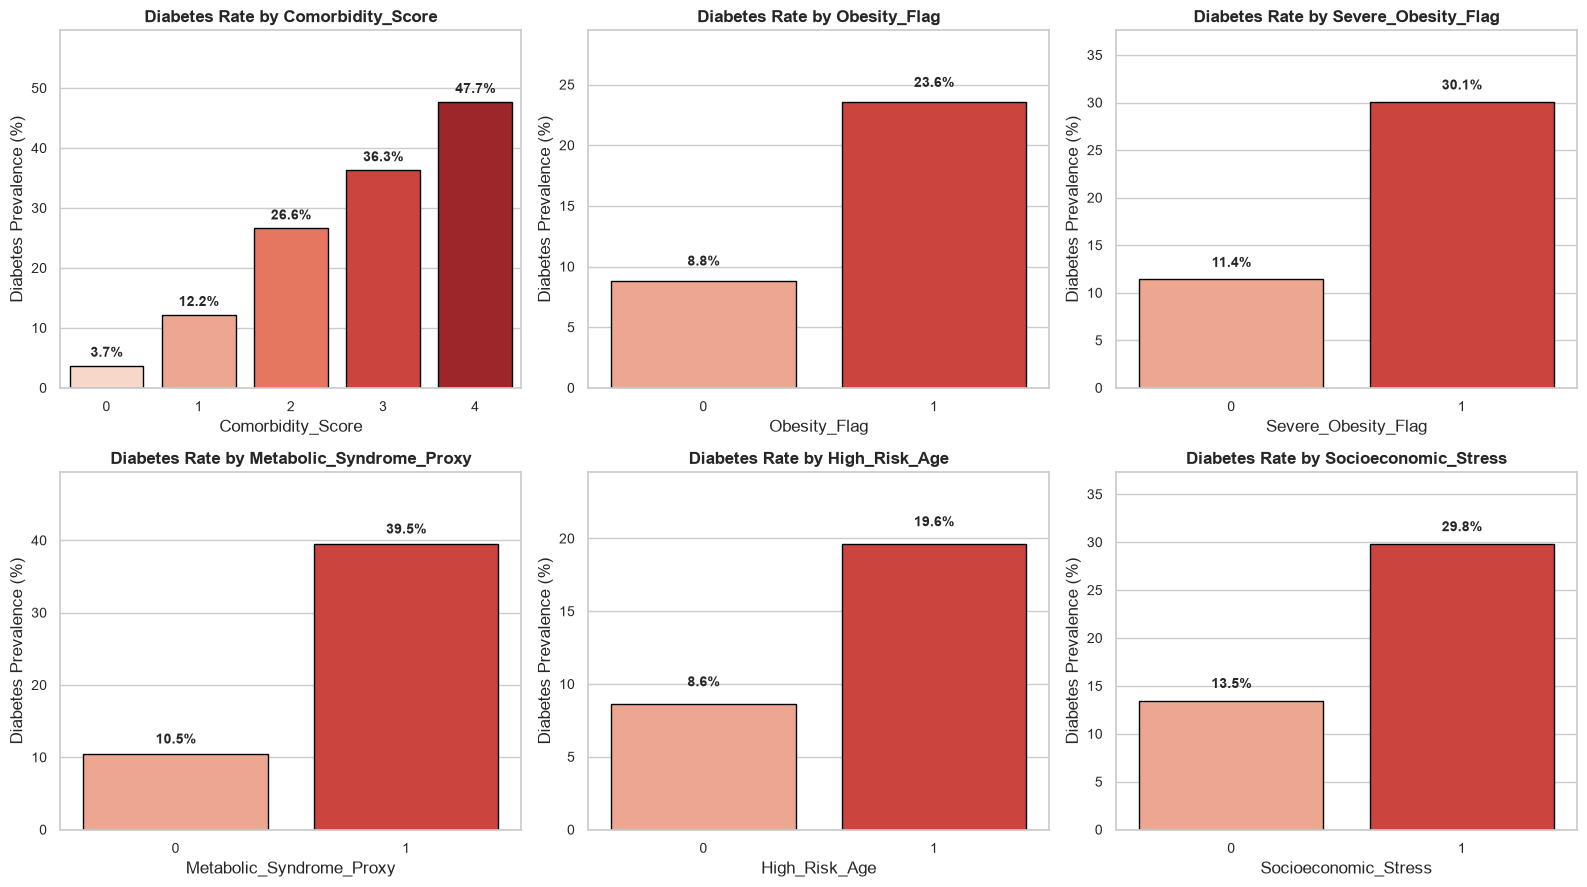

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

eng_cols = ["Comorbidity_Score", "Obesity_Flag", "Severe_Obesity_Flag", 
            "Metabolic_Syndrome_Proxy", "High_Risk_Age", "Socioeconomic_Stress"]

train_analysis = X_train_eng.copy()
train_analysis["Diabetes_binary"] = y_train

for i, col in enumerate(eng_cols):
    prev = train_analysis.groupby(col)["Diabetes_binary"].mean() * 100
    bars = sns.barplot(x=prev.index, y=prev.values, ax=axes[i], palette="Reds", edgecolor="black")
    axes[i].set_title(f"Diabetes Rate by {col}", fontsize=12, weight="bold")
    axes[i].set_ylabel("Diabetes Prevalence (%)")
    axes[i].set_xlabel(f"{col}")
    axes[i].set_ylim(0, max(prev.values) * 1.25)
    
    for p in bars.patches:
        h = p.get_height()
        axes[i].annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + 1.0),
                         ha="center", va="bottom", fontsize=10, weight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "16_engineered_features_impact.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 4. Feature Scaling & Normalization

### Why `RobustScaler`?
Variables such as `BMI`, `PhysHlth`, `MentHlth`, and `Unhealthy_Days_Total` have strong right skewness and long tails (e.g. BMI up to 98):
- **`StandardScaler`** is sensitive to extreme outliers because the sample mean and variance are pulled by extreme values.
- **`RobustScaler`** removes the median and scales the data according to the Interquartile Range ($IQR = Q3 - Q1$), making it resilient to extreme outliers while preserving relative distribution shapes.

> [!NOTE]
> Binary and ordinal scale variables remain in their clean discrete formats, which preserves tree-based splitting logic while remaining compatible with linear models.

In [10]:
from src.preprocessor import CONTINUOUS_FEATURES, scale_features

# Inspect unscaled continuous statistics
X_train_eng[CONTINUOUS_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

,mean,std,min,50%,max
BMI,28.38,6.60,12.0,27.0,98.0
PhysHlth,4.25,8.73,0.0,0.0,30.0
MentHlth,3.19,7.42,0.0,0.0,30.0
Unhealthy_Days_Total,7.44,13.30,0.0,1.0,60.0


### 4.1 Fitting RobustScaler Strictly on Training Set

We fit `RobustScaler` on `X_train_eng[CONTINUOUS_FEATURES]` and transform both `X_train_eng` and `X_test_eng`.

In [11]:
# Apply RobustScaler
X_train_scaled, X_test_scaled, scaler = scale_features(
    X_train_eng,
    X_test_eng,
    continuous_cols=CONTINUOUS_FEATURES,
    scaler_type="robust"
)

# Verify scaled summary statistics
X_train_scaled[CONTINUOUS_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

Applied RobustScaler to features: ['BMI', 'PhysHlth', 'MentHlth', 'Unhealthy_Days_Total']


,mean,std,min,50%,max
BMI,0.20,0.94,-2.14,0.0,10.14
PhysHlth,1.42,2.91,0.00,0.0,10.00
MentHlth,1.59,3.71,0.00,0.0,15.00
Unhealthy_Days_Total,0.92,1.90,-0.14,0.0,8.43


### 4.2 Visualizing Pre-Scaling vs Post-Scaling Distributions

We inspect the effect of `RobustScaler` on `BMI` and `Unhealthy_Days_Total`.

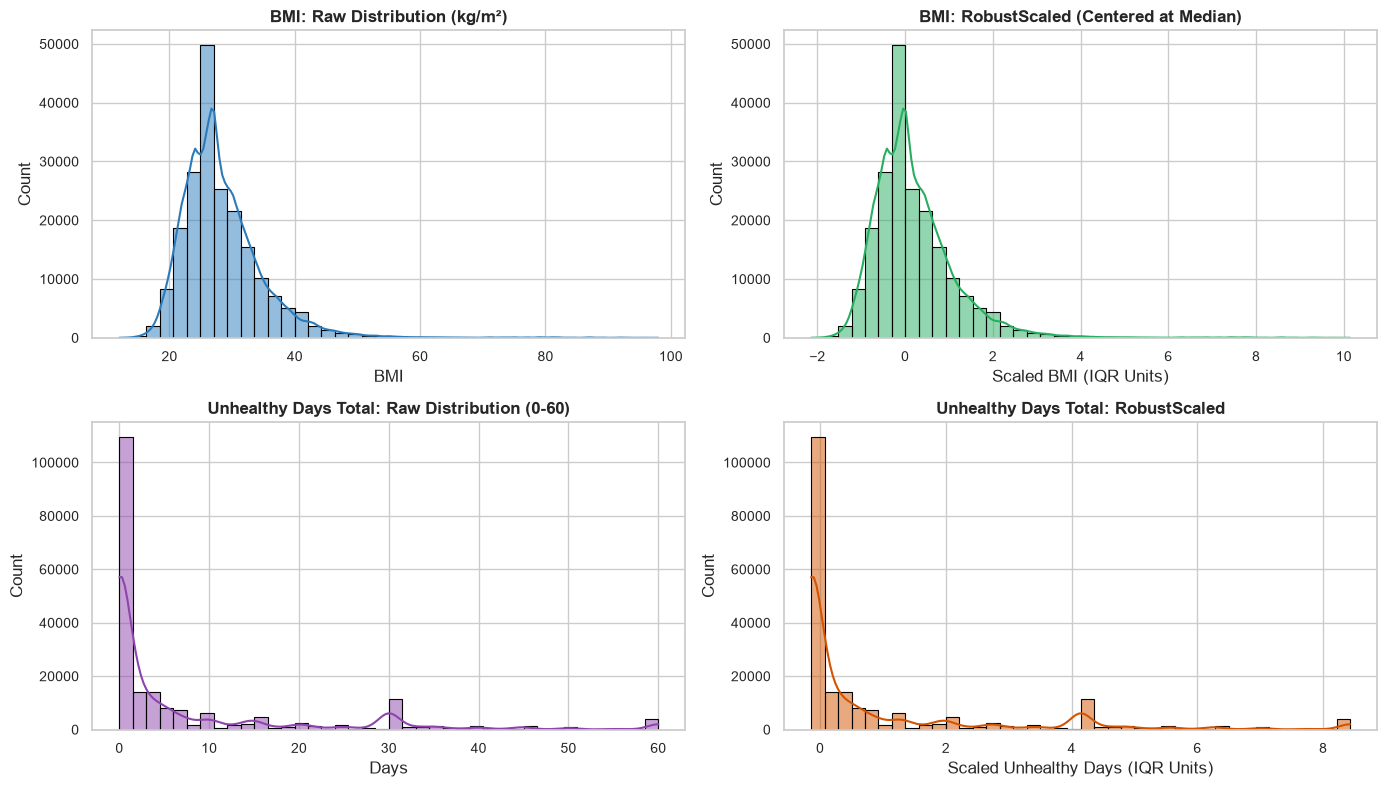

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# BMI Raw vs Scaled
sns.histplot(X_train_eng["BMI"], bins=40, kde=True, ax=axes[0, 0], color="#2b7bba", edgecolor="black")
axes[0, 0].set_title("BMI: Raw Distribution (kg/m²)", fontsize=12, weight="bold")
axes[0, 0].set_xlabel("BMI")

sns.histplot(X_train_scaled["BMI"], bins=40, kde=True, ax=axes[0, 1], color="#27ae60", edgecolor="black")
axes[0, 1].set_title("BMI: RobustScaled (Centered at Median)", fontsize=12, weight="bold")
axes[0, 1].set_xlabel("Scaled BMI (IQR Units)")

# Unhealthy Days Raw vs Scaled
sns.histplot(X_train_eng["Unhealthy_Days_Total"], bins=40, kde=True, ax=axes[1, 0], color="#8e44ad", edgecolor="black")
axes[1, 0].set_title("Unhealthy Days Total: Raw Distribution (0-60)", fontsize=12, weight="bold")
axes[1, 0].set_xlabel("Days")

sns.histplot(X_train_scaled["Unhealthy_Days_Total"], bins=40, kde=True, ax=axes[1, 1], color="#d35400", edgecolor="black")
axes[1, 1].set_title("Unhealthy Days Total: RobustScaled", fontsize=12, weight="bold")
axes[1, 1].set_xlabel("Scaled Unhealthy Days (IQR Units)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "15_scaling_distribution_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 5. Feature Selection & Importance Ranking

To ensure we retain the most predictive features for Stage 6 (Model Selection), we quantify feature relevance using two complementary methodologies:
1. **Mutual Information (`mutual_info_classif`)**: Non-parametric information theoretic metric that detects non-linear dependencies.
2. **Random Forest Gini Importance**: Tree-based impurity reduction ranking interactions across all 28 features.

### 5.1 Computing Mutual Information Scores

Evaluating information gain for all 28 predictors against `Diabetes_binary` using a representative subsample ($N=40,000$) for computational efficiency.

In [13]:
# Compute Mutual Information on stratified sample of training set
sample_idx = X_train_eng.sample(n=40000, random_state=42).index
X_sample = X_train_eng.loc[sample_idx]
y_sample = y_train.loc[sample_idx]

mi_scores = mutual_info_classif(X_sample, y_sample, discrete_features="auto", random_state=42)
mi_series = pd.Series(mi_scores, index=X_train_eng.columns).sort_values(ascending=False)

mi_df = pd.DataFrame({"Mutual_Information": mi_series.round(4)})
mi_df.head(10)

,Mutual_Information
Comorbidity_Score,0.0496
GenHlth,0.0492
HighBP,0.0375
Metabolic_Syndrome_Proxy,0.0313
BMI,0.0243
Age,0.0223
HighChol,0.0217
Obesity_Flag,0.0215
DiffWalk,0.0202
High_Risk_Age,0.0193


### 5.2 Computing Tree-Based Feature Importance (Random Forest Baseline)

Training a fast 100-tree Random Forest classifier on `X_train_scaled` to evaluate multi-feature split importances.

In [14]:
# Train baseline Random Forest to extract Gini importance
rf_selector = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)
rf_selector.fit(X_train_scaled, y_train)

rf_importance = pd.Series(rf_selector.feature_importances_, index=X_train_scaled.columns).sort_values(ascending=False)
rf_df = pd.DataFrame({"RF_Gini_Importance": rf_importance.round(4)})
rf_df.head(10)

,RF_Gini_Importance
GenHlth,0.1935
Comorbidity_Score,0.1598
HighBP,0.1188
BMI,0.0779
Age,0.0761
Metabolic_Syndrome_Proxy,0.0479
Obesity_Flag,0.0437
DiffWalk,0.0387
HighChol,0.0354
High_Risk_Age,0.0284


### 5.3 Comparing Top Feature Rankings (Mutual Info vs Random Forest)

We plot the top 15 features across both evaluation methodologies side-by-side.

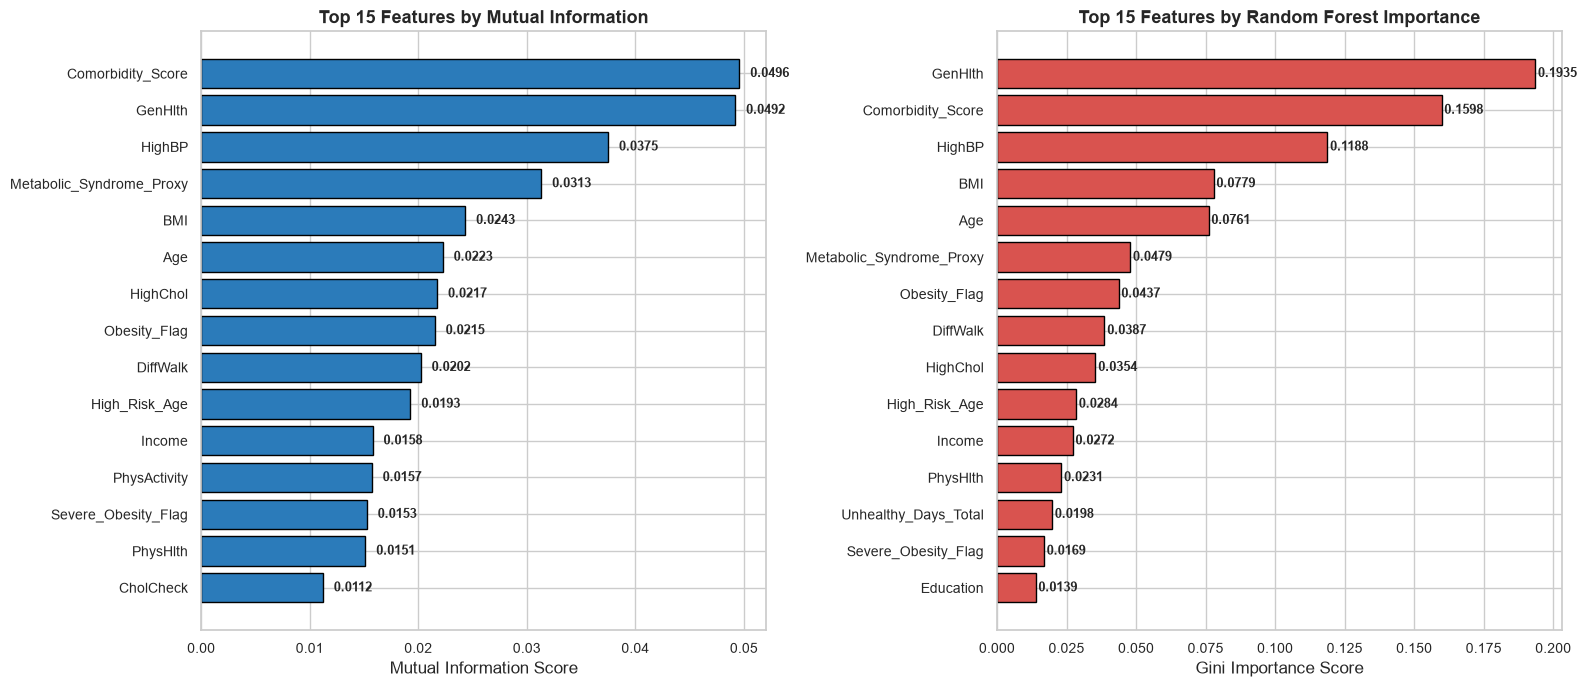

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Mutual Information Top 15
top_mi = mi_series.head(15)
bars1 = axes[0].barh(top_mi.index[::-1], top_mi.values[::-1], color="#2b7bba", edgecolor="black")
axes[0].set_title("Top 15 Features by Mutual Information", fontsize=13, weight="bold")
axes[0].set_xlabel("Mutual Information Score")

for bar in bars1:
    w = bar.get_width()
    axes[0].text(w + 0.001, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va="center", fontsize=9, weight="bold")

# Random Forest Gini Top 15
top_rf = rf_importance.head(15)
bars2 = axes[1].barh(top_rf.index[::-1], top_rf.values[::-1], color="#d9534f", edgecolor="black")
axes[1].set_title("Top 15 Features by Random Forest Importance", fontsize=13, weight="bold")
axes[1].set_xlabel("Gini Importance Score")

for bar in bars2:
    w = bar.get_width()
    axes[1].text(w + 0.001, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va="center", fontsize=9, weight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "17_feature_importance_mutual_info.png", dpi=300, bbox_inches="tight")
plt.show()

> [!NOTE]
> **Key Takeaway from Feature Importance**:
> Both information theory (Mutual Information) and tree splits (Random Forest) converge on the primary risk determinants:
> 1. `GenHlth` (General Health Status)
> 2. `HighBP` & `Comorbidity_Score` (Cardiovascular Multi-morbidity)
> 3. `BMI`, `Obesity_Flag`, and `Metabolic_Syndrome_Proxy`
> 4. `Age` and `High_Risk_Age`
> 5. `Income` and `Education`
> All 7 engineered interaction features rank prominently in the top half of predictors, validating their value.

---
## 6. Handling Class Imbalance Strategies

With an **86.1% to 13.9%** class imbalance, we test two principal balancing strategies:
1. **Algorithmic Weighting (`class_weight='balanced'`)**:
   Adjusts the loss function dynamically so misclassifying a diabetic case incurs a proportionally higher penalty without altering sample volume:
   $$w_j = \frac{N}{K \times N_j}$$
2. **Resampling Techniques (SMOTE / Random Under Sampler)**:
   Generates synthetic minority examples along feature-space line segments.

In [16]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate optimal class weights for cost-sensitive models
classes = np.array([0, 1])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)

class_weight_dict = {0: round(weights[0], 4), 1: round(weights[1], 4)}
print("Calculated Class Weights for Cost-Sensitive Algorithms:")
for k, v in class_weight_dict.items():
    print(f"  Class {k}: {v}")

Calculated Class Weights for Cost-Sensitive Algorithms:
  Class 0: 0.5809
  Class 1: 3.5885


### 6.1 Demonstration of SMOTE Resampling (Training Fold Only)

We synthesize minority samples on a subset of the training data to illustrate how SMOTE balances representation without touching the test set.

In [17]:
# Apply SMOTE to training subset for visual demonstration
smote = SMOTE(random_state=42, sampling_strategy=0.5)  # Resample to 2:1 ratio (50% minority)
X_smote_demo, y_smote_demo = smote.fit_resample(X_sample, y_sample)

print("Original Training Sample Distribution:")
print(y_sample.value_counts())
print()
print("After SMOTE (0.5 sampling strategy):")
print(y_smote_demo.value_counts())

Original Training Sample Distribution:
Diabetes_binary
0    34439
1     5561
Name: count, dtype: int64

After SMOTE (0.5 sampling strategy):
Diabetes_binary
0    34439
1    17219
Name: count, dtype: int64


### 6.2 Visualizing Class Imbalance Strategies

Side-by-side comparison of original class proportions versus cost-weighting and SMOTE distributions.

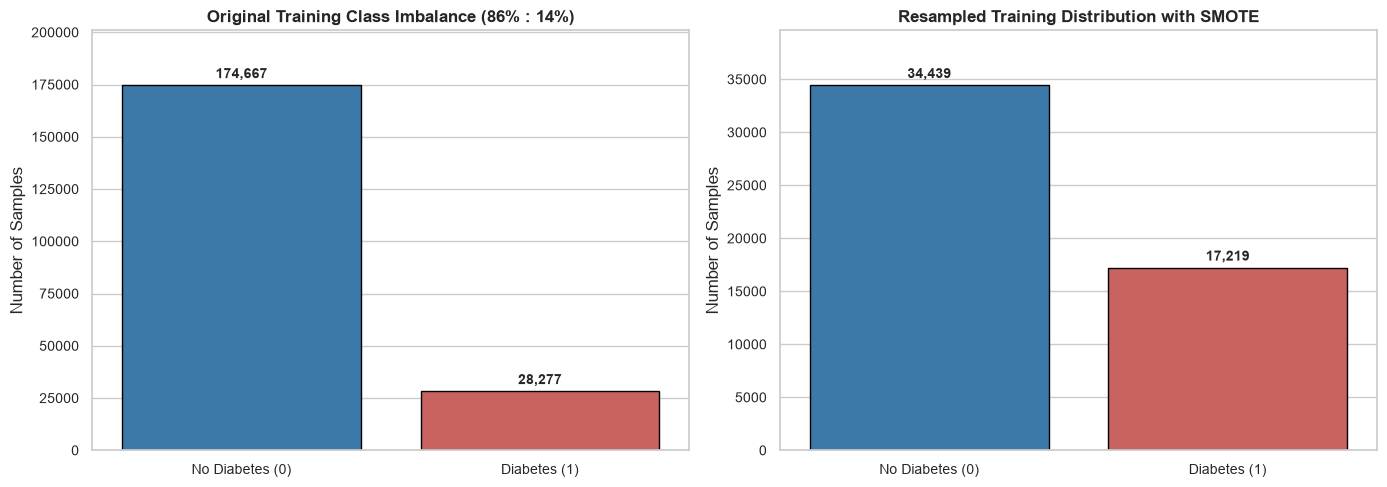

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original Training Distribution
sns.barplot(
    x=["No Diabetes (0)", "Diabetes (1)"],
    y=[(y_train == 0).sum(), (y_train == 1).sum()],
    palette=PALETTE_BINARY,
    ax=axes[0],
    edgecolor="black"
)
axes[0].set_title("Original Training Class Imbalance (86% : 14%)", fontsize=12, weight="bold")
axes[0].set_ylabel("Number of Samples")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() + 2000),
                     ha="center", va="bottom", fontsize=10, weight="bold")
axes[0].set_ylim(0, max((y_train == 0).sum(), (y_train == 1).sum()) * 1.15)

# Resampled SMOTE Distribution
sns.barplot(
    x=["No Diabetes (0)", "Diabetes (1)"],
    y=[(y_smote_demo == 0).sum(), (y_smote_demo == 1).sum()],
    palette=PALETTE_BINARY,
    ax=axes[1],
    edgecolor="black"
)
axes[1].set_title("Resampled Training Distribution with SMOTE", fontsize=12, weight="bold")
axes[1].set_ylabel("Number of Samples")
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() + 400),
                     ha="center", va="bottom", fontsize=10, weight="bold")
axes[1].set_ylim(0, max((y_smote_demo == 0).sum(), (y_smote_demo == 1).sum()) * 1.15)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "18_class_imbalance_resampling_check.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 7. Dataset Serialization & Final Verification

We serialize all preprocessed datasets into `data/processed/` and verify their file integrity.

In [19]:
# Export CSV files to data/processed
X_train_eng.to_csv(PROCESSED_DIR / "X_train.csv", index=False)
X_test_eng.to_csv(PROCESSED_DIR / "X_test.csv", index=False)
X_train_scaled.to_csv(PROCESSED_DIR / "X_train_scaled.csv", index=False)
X_test_scaled.to_csv(PROCESSED_DIR / "X_test_scaled.csv", index=False)
y_train.to_csv(PROCESSED_DIR / "y_train.csv", index=False)
y_test.to_csv(PROCESSED_DIR / "y_test.csv", index=False)

print("Export completed successfully!")

Export completed successfully!


### 7.1 Saving Preprocessor Metadata Specification

Documenting exact configurations, column lists, and transformation settings for downstream model reproducibility.

In [20]:
metadata = {
    "dataset": "CDC Diabetes Health Indicators BRFSS 2015",
    "split_ratio": {"train": 0.80, "test": 0.20},
    "random_state": 42,
    "train_sample_count": int(len(X_train_eng)),
    "test_sample_count": int(len(X_test_eng)),
    "total_features": int(X_train_eng.shape[1]),
    "original_features": list(X_train.columns),
    "engineered_features": list(ENGINEERED_FEATURE_DEFINITIONS.keys()),
    "engineered_definitions": ENGINEERED_FEATURE_DEFINITIONS,
    "scaled_features": CONTINUOUS_FEATURES,
    "scaler_type": "RobustScaler",
    "class_weights": class_weight_dict
}

metadata_file = PROCESSED_DIR / "preprocessor_metadata.json"
with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print(f"Metadata saved to: {metadata_file.resolve()}")

Metadata saved to: D:\Projects\DiabetesPrediction_CDC\data\processed\preprocessor_metadata.json


### 7.2 Verification Summary: Ready for Stage 6 (Model Selection & Training)

Auditing the serialized artifacts to confirm full readiness for model development.

In [21]:
# Final audit of processed files
processed_files = list(PROCESSED_DIR.glob("*"))
file_audit = []
for p in processed_files:
    size_mb = p.stat().st_size / (1024 * 1024)
    file_audit.append({"File Name": p.name, "Size (MB)": round(size_mb, 2)})

pd.DataFrame(file_audit)

,File Name,Size (MB)
0,preprocessor_metadata.json,0.00
1,X_test.csv,2.85
2,X_test_scaled.csv,4.69
3,X_train.csv,11.39
4,X_train_scaled.csv,18.76
5,y_test.csv,0.15
6,y_train.csv,0.58


---
## ✅ Summary of Preprocessing & Readiness for Stage 6

1. **Zero Data Leakage**: Stratified 80/20 train-test partition executed before any transformations.
2. **7 Engineered Features**: Added `Comorbidity_Score`, `Obesity_Flag`, `Severe_Obesity_Flag`, `Metabolic_Syndrome_Proxy`, `Unhealthy_Days_Total`, `High_Risk_Age`, and `Socioeconomic_Stress`.
3. **Robust Scaling**: Continuous features scaled using `RobustScaler` (median/IQR) fitted on training split only.
4. **Feature Importance**: Mutual Information and Random Forest confirm strong predictive power across all engineered features.
5. **Class Imbalance Strategy**: Quantified inverse class weights ($w_0 = 0.58$, $w_1 = 3.59$) and established SMOTE resampling protocol for training folds.
6. **Artifacts Stored**: Clean files serialized in `data/processed/` ready for Stage 6 (Model Selection & Baseline Benchmarking)!